# Projeto Steam Games -  EDA_Portfólio

Olá a todos! Sejam bem-vindos ao meu projeto Steam Games.

Dando sequência ao trabalho iniciado na etapa de ETL, o objetivo desta fase é realizar uma Análise Exploratória de Dados (EDA) em Python. Utilizando as bibliotecas Pandas, Matplotlib e Seaborn, vou extrair insights, identificar padrões e tendências do mercado, além de aprimorar minhas habilidades na construção de visualizações gráficas.

*"Esta Análise Exploratória de Dados (EDA) foi desenvolvida a partir de um conjunto de dados em formato Excel (.xlsx), previamente limpo e tratado na etapa de ETL. Utilizando as bibliotecas Pandas, Matplotlib e Seaborn, foram construídas visualizações estratégicas para extrair insights relevantes sobre o mercado."*

# - Importação, Definição e Carregamento do DataFrame

Neste primeiro momento, fiz a importação de algumas bibliotecas para a realização das atividades. Em seguida, realizei a definição e o carregamento do DataFrame.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

# Carregando o dataset tratado no ETL

df = pd.read_csv("steam_dataset_limpo.csv")

# O preço já está em dólar

df['Price_Formatado'] = df['Price']

df['Release date'] = pd.to_datetime(df['Release date'], errors='coerce')
df['Release Year'] = df['Release date'].dt.year

# 1. A Explosão e Saturação do Mercado
O gráfico abaixo analisa o volume de lançamentos na Steam na última década (2010 a 2025) para entendermos o ritmo de crescimento da plataforma.

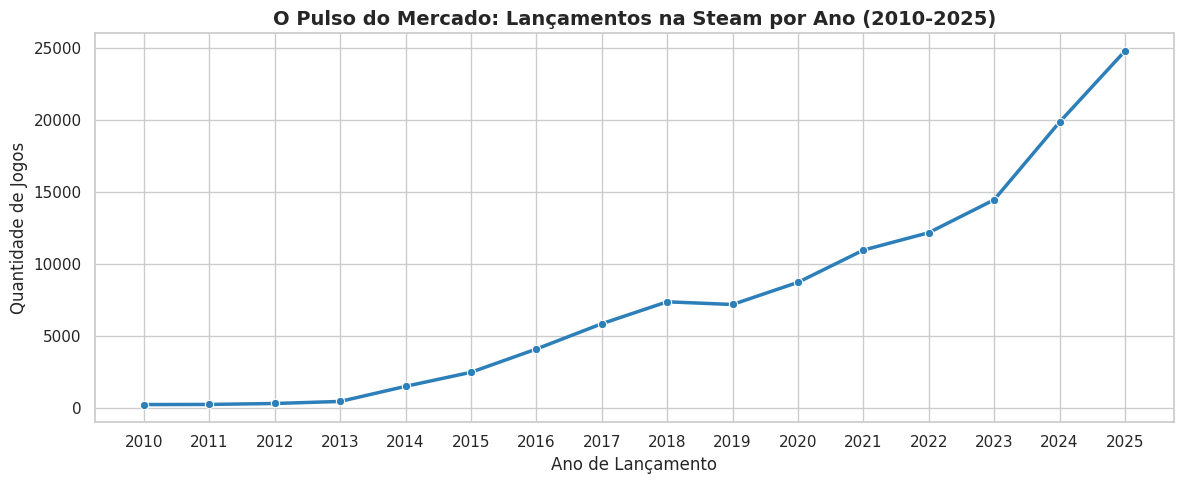

In [8]:
plt.figure(figsize=(12, 5))

df_anos = df[(df['Release Year'] >= 2010) & (df['Release Year'] <= 2025)]
lancamentos_por_ano = df_anos['Release Year'].value_counts().sort_index()

sns.lineplot(x=lancamentos_por_ano.index, y=lancamentos_por_ano.values, marker='o', linewidth=2.5, color="#2c7fb8")

plt.title('O Pulso do Mercado: Lançamentos na Steam por Ano (2010-2025)', fontsize=14, weight='bold')
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Quantidade de Jogos', fontsize=12)
plt.xticks(range(2010, 2026))
plt.tight_layout()
plt.show()

### **Insight 1:**

A análise dos lançamentos entre 2010 e 2025 mostra uma forte expansão do catálogo da Steam. Nos primeiros anos da série, especialmente entre 2010 e 2013, o volume de novos jogos era significativamente menor quando comparado aos anos mais recentes. Esse comportamento pode ser contextualizado pela forma como a Steam funcionava naquele período. Nos primeiros anos, a entrada de novos jogos na plataforma era mais restrita e dependia de um processo de seleção mais controlado pela Valve.

Em 2012, a empresa lançou o Steam Greenlight, permitindo que a própria comunidade participasse da escolha de novos títulos. Posteriormente, em 2017, o Steam Direct substituiu esse sistema e simplificou o processo de publicação, reduzindo as barreiras para desenvolvedores lançarem seus jogos na plataforma.
A partir desse período, observa-se uma aceleração clara no número de lançamentos, com crescimento especialmente forte nos anos mais recentes. Outros fatores, como a popularização de ferramentas de desenvolvimento mais acessíveis e o crescimento do mercado independente, também podem ter contribuído para essa expansão.

Portanto, o gráfico evidencia a transformação da Steam de uma plataforma com catálogo relativamente restrito para um ecossistema com volume muito maior de lançamentos e, consequentemente, maior concorrência entre os títulos.






# 2. O Mito do Preço vs. Engajamento
A hipótese testada aqui é: "Jogadores passam mais tempo em jogos pelos quais pagaram mais caro?".

/tmp/ipykernel_2876/1274323712.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=engajamento_faixa, x='Faixa_Preco', y='Horas_Jogadas', palette='Blues_d')


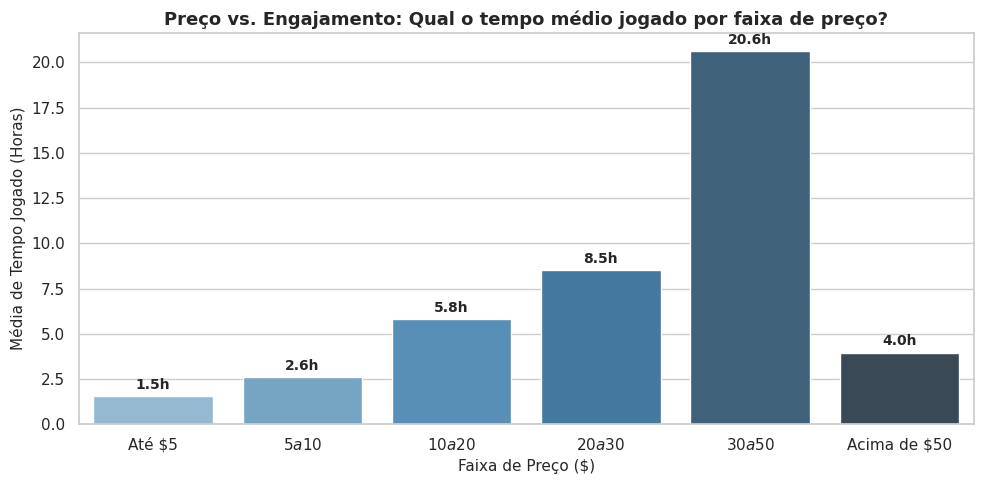

In [9]:
plt.figure(figsize=(10, 5))

# 1. Preparando dados de jogos pagos e convertendo tempo para horas
df_pagos = df[df['Price_Formatado'] > 0].copy()
df_pagos['Horas_Jogadas'] = df_pagos['Median playtime forever'] / 60

# 2. Criando faixas de preço claras
faixas_preco = [0, 5, 10, 20, 30, 50, 1000]
rotulos_preco = ['Até $5', '$5 a $10', '$10 a $20', '$20 a $30', '$30 a $50', 'Acima de $50']
df_pagos['Faixa_Preco'] = pd.cut(df_pagos['Price_Formatado'], bins=faixas_preco, labels=rotulos_preco)

# 3. Calculando a média de horas por faixa
engajamento_faixa = df_pagos.groupby('Faixa_Preco', observed=True)['Horas_Jogadas'].mean().reset_index()

# 4. Plotando o gráfico de barras
ax = sns.barplot(data=engajamento_faixa, x='Faixa_Preco', y='Horas_Jogadas', palette='Blues_d')

plt.title('Preço vs. Engajamento: Qual o tempo médio jogado por faixa de preço?', fontsize=13, weight='bold')
plt.xlabel('Faixa de Preço ($)', fontsize=11)
plt.ylabel('Média de Tempo Jogado (Horas)', fontsize=11)

# Adicionando rótulos com os valores exatos em cima das barras
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(f'{altura:.1f}h',
                (p.get_x() + p.get_width() / 2., altura),
                ha='center', va='bottom', fontsize=10, weight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### **Insight 2:**

A análise mostra que a relação entre preço e tempo médio jogado não é linear. Entre os jogos pagos, o tempo médio aumenta progressivamente nas primeiras faixas de preço:


*   1,5 hora para jogos de até 5 dólares.

*   2,6 horas entre 5 e 10 dólares.

*   5,8 horas entre 10 e 20 dólares.

*   8,5 horas entre 20 e 30 dólares.

O maior destaque aparece na faixa entre 30 e 50 dólares, que apresenta aproximadamente 20,6 horas de tempo médio jogado, valor bastante superior às demais categorias analisadas.

Entretanto, essa tendência não continua nos títulos acima de US$ 50, cuja média cai para aproximadamente 4 horas. Dessa forma, os dados sugerem que preços mais elevados não estão necessariamente associados a maior tempo de jogo.
É importante destacar que essa análise demonstra uma associação dentro do conjunto de dados e não uma relação de causa e efeito. Outros fatores, como gênero, popularidade e características específicas dos jogos presentes em cada faixa, também podem influenciar o tempo de jogo.





# 3. O "Vale da Morte" Indie (Pico de Atenção por Preço)
Como a atenção simultânea dos jogadores se divide entre as diferentes faixas de preço cobradas na loja?

/tmp/ipykernel_2876/1277023695.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ccu_por_categoria, x='Price_Tier', y='Peak CCU', palette='magma')


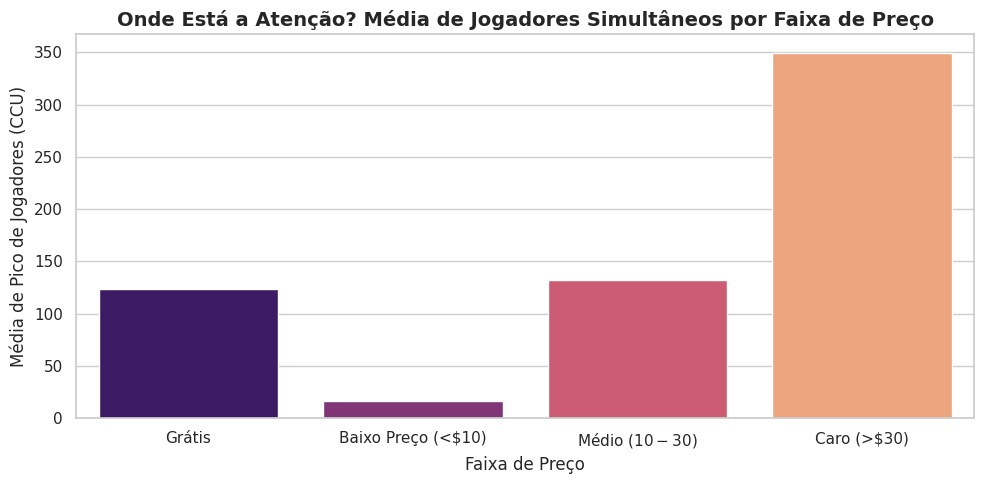

In [10]:
plt.figure(figsize=(10, 5))

bins = [-1, 0.01, 10, 30, 1000]
labels = ['Grátis', 'Baixo Preço (<$10)', 'Médio ($10-$30)', 'Caro (>$30)']
df['Price_Tier'] = pd.cut(df['Price_Formatado'], bins=bins, labels=labels)

ccu_por_categoria = df.groupby('Price_Tier', observed=True)['Peak CCU'].mean().reset_index()
sns.barplot(data=ccu_por_categoria, x='Price_Tier', y='Peak CCU', palette='magma')

plt.title('Onde Está a Atenção? Média de Jogadores Simultâneos por Faixa de Preço', fontsize=14, weight='bold')
plt.xlabel('Faixa de Preço', fontsize=12)
plt.ylabel('Média de Pico de Jogadores (CCU)', fontsize=12)
plt.tight_layout()
plt.show()

### **Insight 3:**

Ao analisar a média do Peak CCU por faixa de preço, observa-se uma diferença expressiva entre as categorias. Os jogos abaixo de US$ 10 apresentam o menor pico médio de jogadores simultâneos, enquanto jogos gratuitos e títulos entre 10 e 30 dólares apresentam valores consideravelmente superiores e relativamente próximos.

O principal destaque aparece entre os jogos com preço acima de US$ 30, que apresentam a maior média de Peak CCU do conjunto analisado, próxima de 350 jogadores simultâneos, contra aproximadamente 130 na faixa intermediária e 120 entre os jogos gratuitos.

Esse resultado sugere que, dentro deste dataset, jogos de preço mais elevado incluem títulos capazes de atingir picos significativamente maiores de jogadores simultâneos. Entretanto, a média pode ser influenciada por alguns títulos de grande popularidade presentes nessa categoria.
Além disso, Peak CCU representa o pico de usuários simultâneos registrado e não o tempo de permanência ou retenção dos jogadores. Portanto, esse indicador deve ser interpretado principalmente como uma medida de alcance ou intensidade máxima de atividade.

# 4. A Elite Absoluta (Top 10 Steam)
Um olhar sobre os gigantes que dominam os servidores da plataforma.

/tmp/ipykernel_2876/2791522201.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='Peak CCU', y='Name', palette='viridis')


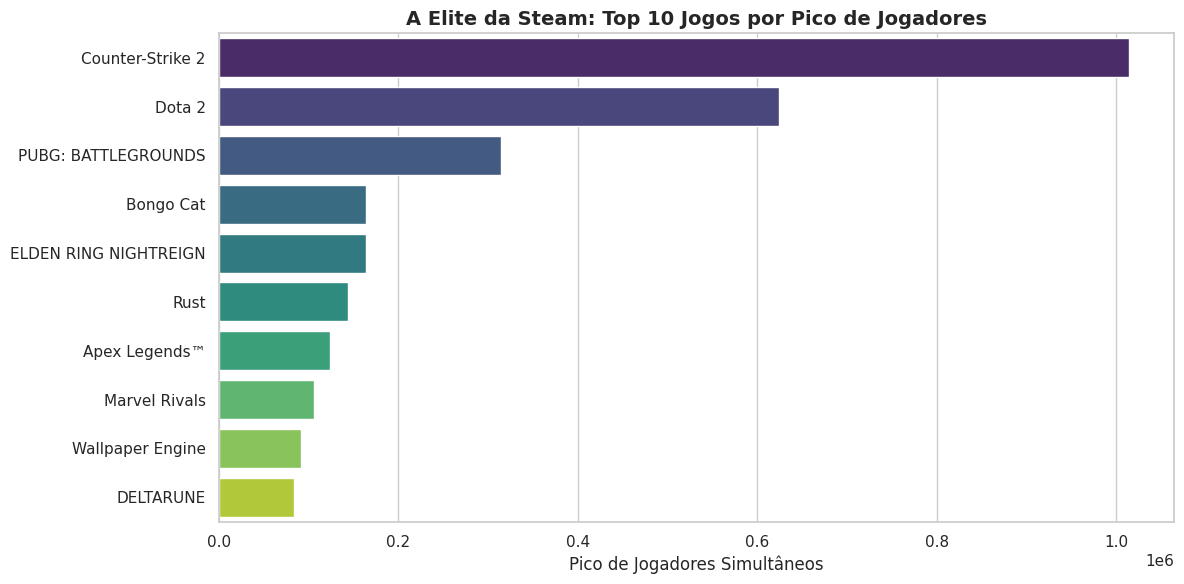

In [11]:
plt.figure(figsize=(12, 6))

top_10 = df.nlargest(10, 'Peak CCU')
sns.barplot(data=top_10, x='Peak CCU', y='Name', palette='viridis')

plt.title('A Elite da Steam: Top 10 Jogos por Pico de Jogadores', fontsize=14, weight='bold')
plt.xlabel('Pico de Jogadores Simultâneos', fontsize=12)
plt.ylabel('')
plt.tight_layout()
plt.show()

### **Insight 4:**

O ranking dos maiores valores de Peak CCU revela uma forte concentração de jogadores em poucos títulos do catálogo. Counter-Strike 2 ocupa a primeira posição, ultrapassando a marca de 1 milhão de jogadores simultâneos, seguido por Dota 2, com aproximadamente 625 mil, e PUBG: BATTLEGROUNDS, com pouco mais de 300 mil.

A partir das primeiras posições ocorre uma queda expressiva nos valores, mostrando que os títulos líderes atingem níveis de atividade bastante superiores aos demais jogos presentes até mesmo no Top 10.

O ranking também apresenta uma composição diversificada, incluindo títulos como Rust, Apex Legends, Marvel Rivals, ELDEN RING NIGHTREIGN, DELTARUNE e até Wallpaper Engine. Isso demonstra que valores elevados de Peak CCU não estão restritos a um único gênero ou modelo de produto.

Dessa forma, o principal padrão identificado é a concentração do pico de usuários em um pequeno grupo de títulos, com uma diferença especialmente pronunciada entre os três primeiros colocados e o restante do ranking.

# 5. O Domínio dos Gêneros: O que a Steam mais joga?

Para finalizar nossa análise, vamos descobrir quais são os gêneros que mais atraem jogadores simultâneos na plataforma. Como um único jogo pode pertencer a vários gêneros (ex: Ação e RPG), vamos separar essas categorias para ver quais acumulam o maior volume de jogadores de pico (Peak CCU).

/tmp/ipykernel_2876/2299634188.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_generos, x='Peak CCU', y='Genres', palette='magma')


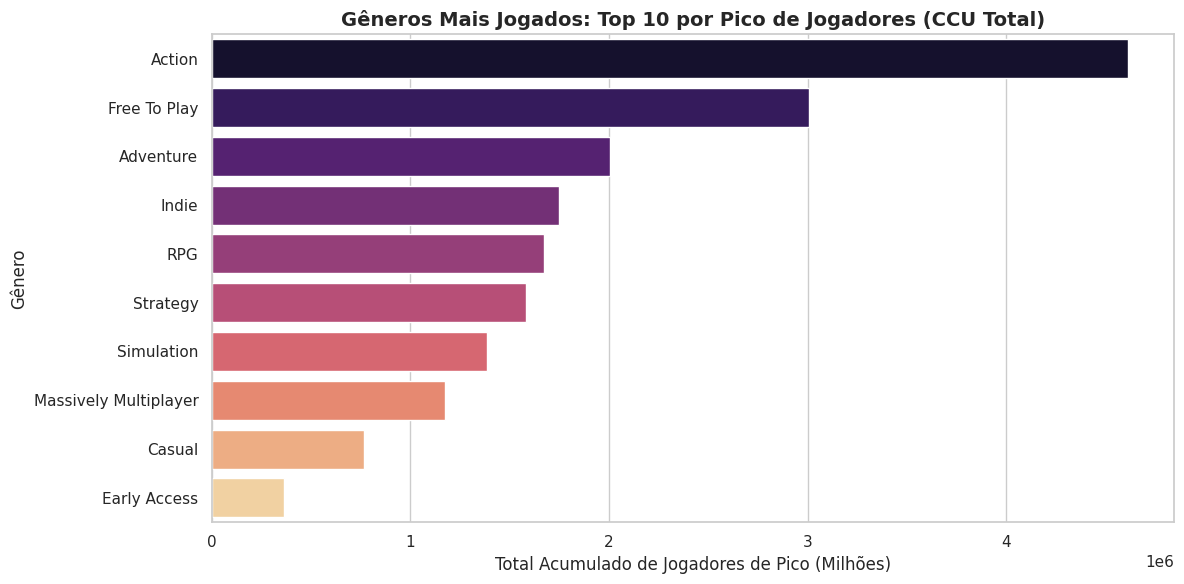

In [12]:
plt.figure(figsize=(12, 6))

# 1. Limpando jogos sem gênero definido e separando os gêneros por vírgula
df_generos = df.dropna(subset=['Genres']).copy()
df_generos['Genres'] = df_generos['Genres'].str.split(',')

# 2. O comando explode 'multiplica' a linha para cada gênero, permitindo contar individualmente
df_expandido = df_generos.explode('Genres')

# 3. Removendo espaços em branco extras que podem ficar após a vírgula
df_expandido['Genres'] = df_expandido['Genres'].str.strip()

# 4. Agrupando pelo Pico de Jogadores (Peak CCU) somado por gênero e pegando o Top 10
top_generos = df_expandido.groupby('Genres')['Peak CCU'].sum().nlargest(10).reset_index()

# 5. Plotando o gráfico de barras horizontais
ax = sns.barplot(data=top_generos, x='Peak CCU', y='Genres', palette='magma')

plt.title('Gêneros Mais Jogados: Top 10 por Pico de Jogadores (CCU Total)', fontsize=14, weight='bold')
plt.xlabel('Total Acumulado de Jogadores de Pico (Milhões)', fontsize=12)
plt.ylabel('Gênero', fontsize=12)

plt.tight_layout()
plt.show()

### **Insight 5:**

A análise do Peak CCU acumulado por gênero mostra uma liderança expressiva de Action (ação), que ultrapassa aproximadamente 4,5 milhões na soma dos picos de jogadores dos títulos associados ao gênero.

Em seguida aparece Free To Play (grátis), próximo de 3 milhões, seguido por Adventure (aventura), com aproximadamente 2 milhões. Gêneros como Indie, RPG e Strategy (estratégia) também apresentam participação relevante, formando um segundo grupo com valores acumulados relativamente próximos.

O resultado mostra que jogos classificados como Action estão fortemente presentes entre os títulos com maiores picos de jogadores do dataset, enquanto Free To Play também se destaca de maneira significativa. Há, entretanto, uma característica importante nesta análise, um mesmo jogo pode possuir mais de um gênero. Como os gêneros foram separados utilizando **'explode()'**, o Peak CCU de um jogo pode contribuir para mais de uma categoria.

Portanto, os valores não representam jogadores únicos por gênero, mas sim o Peak CCU acumulado dos jogos associados a cada gênero.

# - Conclusão da Análise Exploratória (EDA)

A Análise Exploratória dos dados do Steam permitiu identificar diferentes padrões relacionados ao crescimento do catálogo, preços, tempo de jogo, popularidade e gêneros presentes na plataforma.


*   A evolução histórica dos lançamentos demonstra uma forte expansão do catálogo entre 2010 e 2025, com crescimento especialmente intenso nos anos mais recentes. Isso evidencia um ambiente cada vez mais amplo e competitivo em quantidade de títulos disponíveis.

*   A análise de preços revelou que o comportamento dos jogadores não apresenta uma relação linear com o valor dos jogos. A faixa entre 30 e 50 dólares apresentou o maior tempo médio jogado, aproximadamente 20,6 horas, enquanto jogos acima de US$ 50 registraram uma redução significativa nesse indicador.

*   Ao observar o Peak CCU, os títulos acima de US$ 30 apresentaram a maior média de pico de jogadores simultâneos. Paralelamente, o ranking individual revelou uma forte concentração de atividade em poucos títulos, especialmente Counter-Strike 2, Dota 2 e PUBG: BATTLEGROUNDS.

*   Na análise por gênero, Action (ação) apresentou o maior Peak CCU acumulado, seguido por Free To Play (grátis) e Adventure (aventura). Como os jogos podem possuir múltiplos gêneros, esses valores representam a soma dos picos associados às categorias e não uma contagem de jogadores únicos.

De forma geral, os resultados mostram que preço, popularidade e tempo de jogo apresentam comportamentos distintos e não devem ser interpretados isoladamente. Como próxima etapa do projeto, essas informações podem ser integradas a indicadores como Total Ratings e Approval Rate, além da construção de um dashboard no Power BI, permitindo uma análise mais interativa e completa dos dados.